
# Time Series & Category Charts

## Internship: Syntecxhub Data Science

### Project Overview
This project focuses on visualizing sales data using different types of charts. It includes sales trends over time, monthly and quarterly sales aggregation, category-wise comparisons, and sales distribution.

### Objectives
- Plot sales over time using line charts.
- Perform monthly and quarterly sales aggregation.
- Compare categories using bar charts.
- Visualize category share using pie charts.
- Save charts as PNG files.
- Interpret the visualizations and summarize findings.

### Tools & Libraries
- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

ModuleNotFoundError: No module named 'seaborn'

In [3]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
import pandas as pd
import numpy as np

np.random.seed(42)

# 1. Generate dates for 2 years
dates = pd.date_range("2024-01-01", "2025-12-31", freq="D")

# 2. Product categories and products
products = {
    "Electronics": {
        "Laptop": 55000,
        "Mobile": 25000,
        "Headphones": 2500,
        "Keyboard": 1200,
        "Smartwatch": 5000
    },
    "Clothing": {
        "T-Shirt": 800,
        "Jeans": 1800,
        "Shoes": 3000,
        "Jacket": 3500,
        "Shirt": 1500
    },
    "Furniture": {
        "Chair": 4500,
        "Table": 8000,
        "Sofa": 25000,
        "Bed": 30000,
        "Bookshelf": 7000
    },
    "Groceries": {
        "Rice": 100,
        "Oil": 150,
        "Milk": 60,
        "Sugar": 50,
        "Flour": 45
    }
}

# 3. Regions and cities
region_cities = {
    "North": ["Delhi", "Jaipur", "Chandigarh", "Lucknow"],
    "South": ["Chennai", "Bengaluru", "Hyderabad", "Kochi"],
    "East": ["Kolkata", "Patna", "Bhubaneswar", "Ranchi"],
    "West": ["Mumbai", "Pune", "Ahmedabad", "Surat"]
}

categories = list(products.keys())
regions = list(region_cities.keys())

# 4. Generate 5000 records
n = 5000

sales_dates = np.random.choice(dates, n)
sales_categories = np.random.choice(categories, n)
sales_regions = np.random.choice(regions, n)
quantities = np.random.randint(1, 11, n)
discounts = np.random.choice([0, 5, 10, 15, 20], n)

# 5. Generate products and prices matching each category
selected_products = []
unit_prices = []
cities = []

for i in range(n):
    category = sales_categories[i]

    product = np.random.choice(list(products[category].keys()))
    price = products[category][product]

    region = sales_regions[i]
    city = np.random.choice(region_cities[region])

    selected_products.append(product)
    unit_prices.append(price)
    cities.append(city)

# 6. Create the main sales dataset
df = pd.DataFrame({
    "Order_ID": range(10001, 10001 + n),
    "Date": sales_dates,
    "Category": sales_categories,
    "Product": selected_products,
    "Region": sales_regions,
    "City": cities,
    "Quantity": quantities,
    "Unit_Price": unit_prices,
    "Discount_Percent": discounts
})

# 7. Calculate sales and profit
df["Gross_Sales"] = df["Quantity"] * df["Unit_Price"]

df["Discount_Amount"] = (
    df["Gross_Sales"] * df["Discount_Percent"] / 100
)

df["Sales"] = df["Gross_Sales"] - df["Discount_Amount"]

# Estimated product cost (different cost percentages)
cost_percentages = {
    "Electronics": 0.75,
    "Clothing": 0.55,
    "Furniture": 0.65,
    "Groceries": 0.85
}

df["Estimated_Cost"] = (
    df["Gross_Sales"] *
    df["Category"].map(cost_percentages)
)

df["Profit"] = df["Sales"] - df["Estimated_Cost"]

# 8. Sort by date
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# 9. Display dataset
print("Dataset created successfully!")
print("Total records:", len(df))

df.head(10)

Dataset created successfully!
Total records: 5000


,Order_ID,Date,Category,Product,Region,City,Quantity,Unit_Price,Discount_Percent,Gross_Sales,Discount_Amount,Sales,Estimated_Cost,Profit
0,14163,2024-01-01,Groceries,Milk,North,Lucknow,1,60,15,60,9.0,51.0,51.0,0.0
1,13251,2024-01-01,Furniture,Bed,South,Kochi,6,30000,5,180000,9000.0,171000.0,117000.0,54000.0
2,11138,2024-01-01,Furniture,Sofa,East,Kolkata,9,25000,0,225000,0.0,225000.0,146250.0,78750.0
3,12035,2024-01-01,Clothing,Jacket,South,Bengaluru,3,3500,10,10500,1050.0,9450.0,5775.0,3675.0
4,10649,2024-01-01,Electronics,Smartwatch,East,Bhubaneswar,9,5000,10,45000,4500.0,40500.0,33750.0,6750.0
5,10756,2024-01-01,Furniture,Sofa,South,Kochi,8,25000,20,200000,40000.0,160000.0,130000.0,30000.0
6,13557,2024-01-01,Clothing,Shirt,West,Surat,9,1500,15,13500,2025.0,11475.0,7425.0,4050.0
7,10980,2024-01-01,Groceries,Oil,East,Kolkata,1,150,10,150,15.0,135.0,127.5,7.5
8,11978,2024-01-01,Groceries,Flour,North,Lucknow,4,45,0,180,0.0,180.0,153.0,27.0
9,13052,2024-01-01,Clothing,Jeans,North,Chandigarh,6,1800,15,10800,1620.0,9180.0,5940.0,3240.0


In [6]:
# Check dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (5000, 14)

Column Names:
['Order_ID', 'Date', 'Category', 'Product', 'Region', 'City', 'Quantity', 'Unit_Price', 'Discount_Percent', 'Gross_Sales', 'Discount_Amount', 'Sales', 'Estimated_Cost', 'Profit']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          5000 non-null   int64         
 1   Date              5000 non-null   datetime64[us]
 2   Category          5000 non-null   str           
 3   Product           5000 non-null   str           
 4   Region            5000 non-null   str           
 5   City              5000 non-null   str           
 6   Quantity          5000 non-null   int32         
 7   Unit_Price        5000 non-null   int64         
 8   Discount_Percent  5000 non-null   int64         
 9   Gross_Sales       5000 non-null   int64         
 10  Discount_

,Order_ID,Date,Quantity,Unit_Price,Discount_Percent,Gross_Sales,Discount_Amount,Sales,Estimated_Cost,Profit
count,5000.000000,5000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,2025-01-02 01:37:37.920000,5.483600,8539.90300,9.846000,46049.216000,4342.028800,41707.187200,31948.767600,9758.419600
min,10001.000000,2024-01-01 00:00:00,1.000000,45.00000,0.000000,45.000000,0.000000,36.000000,38.250000,-75.000000
25%,11250.750000,2024-07-01 00:00:00,3.000000,800.00000,5.000000,1350.000000,18.000000,1200.000000,990.000000,180.000000
50%,12500.500000,2025-01-04 12:00:00,5.000000,3000.00000,10.000000,12000.000000,600.000000,10710.000000,7462.500000,3000.000000
75%,13750.250000,2025-07-07 00:00:00,8.000000,7000.00000,15.000000,40000.000000,3150.000000,36000.000000,26325.000000,9600.000000
max,15000.000000,2025-12-31 00:00:00,10.000000,55000.00000,20.000000,550000.000000,110000.000000,550000.000000,412500.000000,137500.000000
std,1443.520003,NaN,2.860029,13755.16694,7.078581,86786.467013,10279.545054,79353.995239,63032.111991,17998.674845


In [7]:
# Basic Sales Analysis

print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Orders:", df["Order_ID"].nunique())
print("Total Units Sold:", df["Quantity"].sum())

print("\nAverage Order Sales:", round(df["Sales"].mean(), 2))
print("Highest Sale:", round(df["Sales"].max(), 2))
print("Lowest Sale:", round(df["Sales"].min(), 2))

print("\nCategory-wise Sales:")
print(df.groupby("Category")["Sales"].sum().sort_values(ascending=False))

print("\nRegion-wise Sales:")
print(df.groupby("Region")["Sales"].sum().sort_values(ascending=False))

Total Sales: 208535936.0
Total Profit: 48792098.0
Total Orders: 5000
Total Units Sold: 27418

Average Order Sales: 41707.19
Highest Sale: 550000.0
Lowest Sale: 36.0

Category-wise Sales:
Category
Electronics    104290105.0
Furniture       90241125.0
Clothing        13497100.0
Groceries         507606.0
Name: Sales, dtype: float64

Region-wise Sales:
Region
South    54615871.75
North    52502227.50
East     51986743.50
West     49431093.25
Name: Sales, dtype: float64


In [8]:
# Monthly Sales Summary

df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

monthly_sales["Month"] = monthly_sales["Month"].astype(str)

monthly_sales.head(12)

,Month,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,2024-01,8742826.25,2047414.50,214,1176
1,2024-02,7800324.00,1796138.50,192,1033
2,2024-03,9518358.75,2192408.25,204,1098
3,2024-04,7625619.25,2027537.00,221,1258
4,2024-05,7226402.25,1785258.50,209,1117
5,2024-06,7856622.25,1819575.50,207,1102
6,2024-07,9040078.75,2132353.00,206,1187
7,2024-08,8482411.00,1963369.50,216,1158
8,2024-09,7558457.75,1769009.25,192,1105
9,2024-10,7974512.50,1855661.25,212,1151


In [9]:
# Category-wise Sales Summary

category_summary = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

category_summary = category_summary.sort_values(
    "Total_Sales", ascending=False
)

category_summary

,Category,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
1,Electronics,104290105.0,18245905.0,1236,6605
2,Furniture,90241125.0,25278175.0,1247,6942
0,Clothing,13497100.0,5239455.0,1293,7015
3,Groceries,507606.0,28563.0,1224,6856


In [10]:
# Region-wise Sales Summary

region_summary = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

region_summary = region_summary.sort_values(
    "Total_Sales", ascending=False
)

region_summary

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
2,South,54615871.75,12770806.5,1216,6719
1,North,52502227.50,12375288.5,1306,7292
0,East,51986743.50,12047782.0,1253,6892
3,West,49431093.25,11598221.0,1225,6515


In [11]:
# Product-wise Sales Summary

product_summary = df.groupby(["Category", "Product"]).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

product_summary = product_summary.sort_values(
    "Total_Sales", ascending=False
)

product_summary.head(15)

,Category,Product,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
7,Electronics,Laptop,67122000.0,12094500.0,247,1334
10,Furniture,Bed,34020000.0,9489000.0,235,1258
13,Furniture,Sofa,31087500.0,8711250.0,251,1377
8,Electronics,Mobile,26768750.0,4418750.0,234,1192
11,Furniture,Bookshelf,10507700.0,2991100.0,291,1652
14,Furniture,Table,8843200.0,2504400.0,221,1219
9,Electronics,Smartwatch,6006750.0,1019250.0,249,1330
12,Furniture,Chair,5782725.0,1582425.0,249,1436
0,Clothing,Jacket,4453575.0,1708525.0,270,1426
3,Clothing,Shoes,3965400.0,1539900.0,259,1470


In [12]:
# City-wise Sales Summary

city_summary = df.groupby(["Region", "City"]).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count")
).reset_index()

city_summary = city_summary.sort_values(
    "Total_Sales", ascending=False
)

city_summary.head(15)

,Region,City,Total_Sales,Total_Profit,Total_Orders
10,South,Hyderabad,15157379.75,3766095.75,323
4,North,Chandigarh,14648923.50,3404863.75,303
7,North,Lucknow,14300084.00,3530334.00,347
9,South,Chennai,13994720.50,3155641.00,322
2,East,Patna,13607996.00,3104831.25,295
11,South,Kochi,13481707.50,3172069.00,285
0,East,Bhubaneswar,13430053.00,3084832.25,312
15,West,Surat,13300705.00,3102678.75,305
3,East,Ranchi,13022615.25,3012760.00,329
13,West,Mumbai,13007195.00,2972694.25,322


In [13]:
# Save all project datasets as CSV files

df.to_csv("sales_dataset.csv", index=False)
monthly_sales.to_csv("monthly_sales_summary.csv", index=False)
quarterly_sales.to_csv("quarterly_sales_summary.csv", index=False)
category_summary.to_csv("category_sales_summary.csv", index=False)
region_summary.to_csv("region_sales_summary.csv", index=False)
product_summary.to_csv("product_sales_summary.csv", index=False)
city_summary.to_csv("city_sales_summary.csv", index=False)

print("All CSV files saved successfully!")

NameError: name 'quarterly_sales' is not defined

In [14]:
df["Quarter"] = df["Date"].dt.to_period("Q")

quarterly_sales = df.groupby("Quarter").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

quarterly_sales["Quarter"] = quarterly_sales["Quarter"].astype(str)

quarterly_sales

,Quarter,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,2024Q1,26061509.00,6035961.25,610,3307
1,2024Q2,22708643.75,5632371.00,637,3477
2,2024Q3,25080947.50,5864731.75,614,3450
3,2024Q4,27271480.75,6239714.50,616,3376
4,2025Q1,27595343.00,6378349.00,618,3412
5,2025Q2,26624114.25,6245300.75,603,3384
6,2025Q3,26116857.00,5917672.50,647,3516
7,2025Q4,27077040.75,6477997.25,655,3496


In [15]:
# Save all project datasets as CSV files

df.to_csv("sales_dataset.csv", index=False)
monthly_sales.to_csv("monthly_sales_summary.csv", index=False)
quarterly_sales.to_csv("quarterly_sales_summary.csv", index=False)
category_summary.to_csv("category_sales_summary.csv", index=False)
region_summary.to_csv("region_sales_summary.csv", index=False)
product_summary.to_csv("product_sales_summary.csv", index=False)
city_summary.to_csv("city_sales_summary.csv", index=False)

print("All CSV files saved successfully!")

All CSV files saved successfully!


In [16]:
import os

files = os.listdir()

for file in files:
    if file.endswith(".csv"):
        print(file)

category_sales_summary.csv
city_sales_summary.csv
monthly_sales_summary.csv
product_sales_summary.csv
quarterly_sales_summary.csv
region_sales_summary.csv
sales_dataset.csv


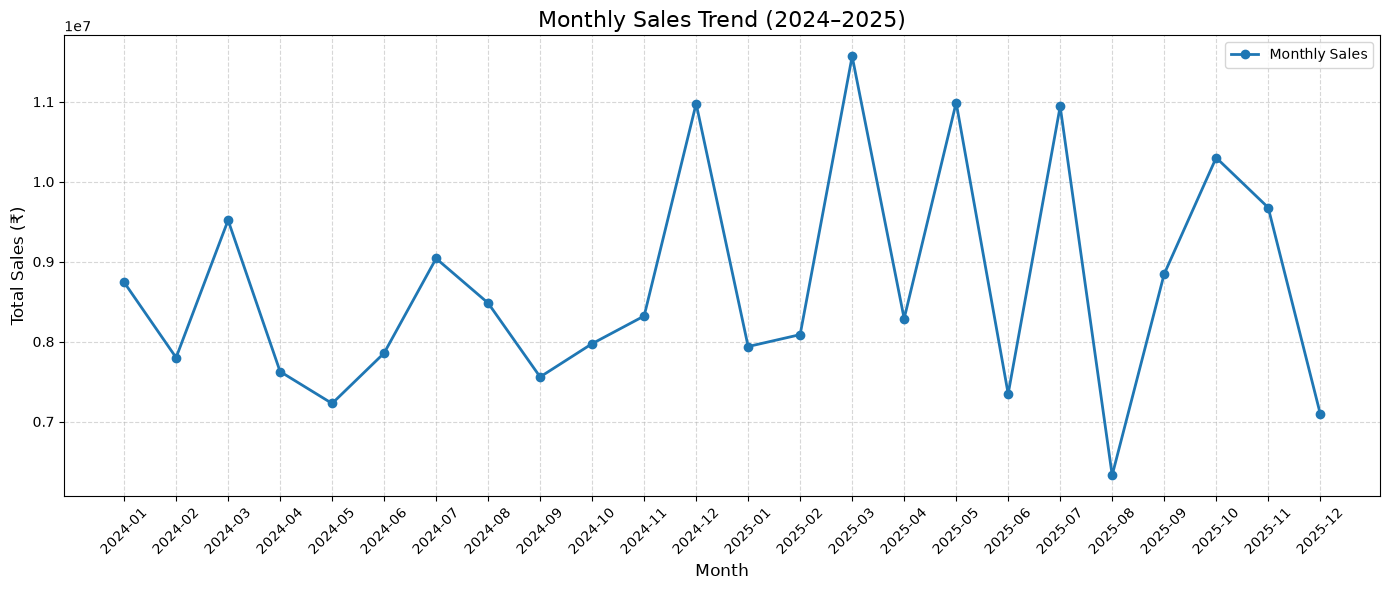

In [17]:
# Line Chart - Monthly Sales Trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Total_Sales"],
    marker="o",
    linewidth=2,
    label="Monthly Sales"
)

plt.title("Monthly Sales Trend (2024–2025)", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales (₹)", fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

# Save chart
plt.savefig("monthly_sales_line_chart.png", dpi=300)

plt.show()

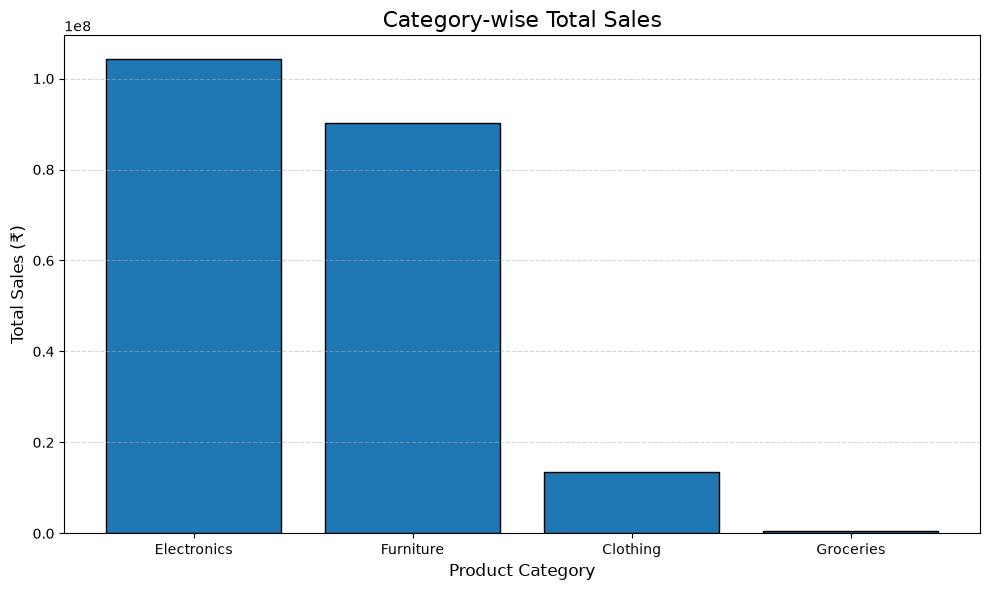

In [18]:
# Bar Chart - Category-wise Sales

plt.figure(figsize=(10, 6))

plt.bar(
    category_summary["Category"],
    category_summary["Total_Sales"],
    edgecolor="black"
)

plt.title("Category-wise Total Sales", fontsize=16)
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Sales (₹)", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

# Save chart
plt.savefig("category_sales_bar_chart.png", dpi=300)

plt.show()

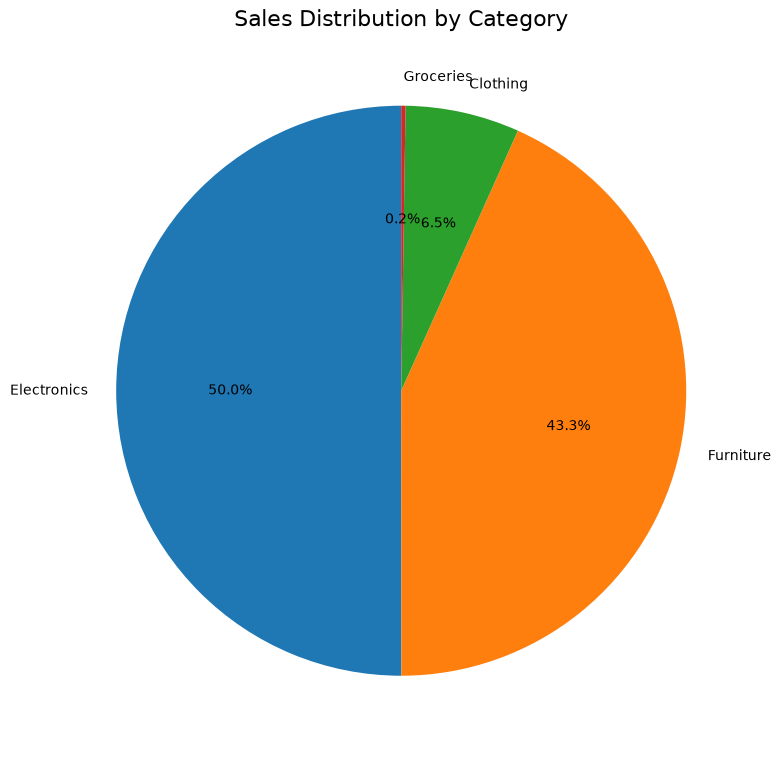

In [19]:
# Pie Chart - Category Sales Distribution

plt.figure(figsize=(8, 8))

plt.pie(
    category_summary["Total_Sales"],
    labels=category_summary["Category"],
    autopct="%1.1f%%",
    startangle=90,
    shadow=False
)

plt.title("Sales Distribution by Category", fontsize=16)
plt.tight_layout()

# Save chart
plt.savefig("category_sales_pie_chart.png", dpi=300)

plt.show()

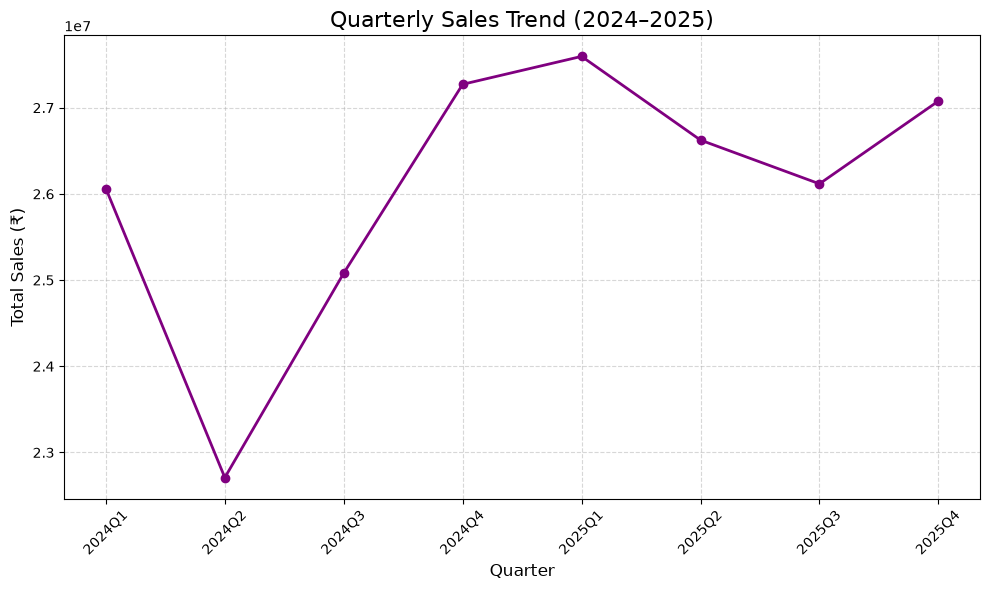

In [20]:
# Quarterly Sales Chart

plt.figure(figsize=(10, 6))

plt.plot(
    quarterly_sales["Quarter"],
    quarterly_sales["Total_Sales"],
    marker="o",
    color="purple",
    linewidth=2
)

plt.title("Quarterly Sales Trend (2024–2025)", fontsize=16)
plt.xlabel("Quarter", fontsize=12)
plt.ylabel("Total Sales (₹)", fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Save chart
plt.savefig("quarterly_sales_chart.png", dpi=300)

plt.show()

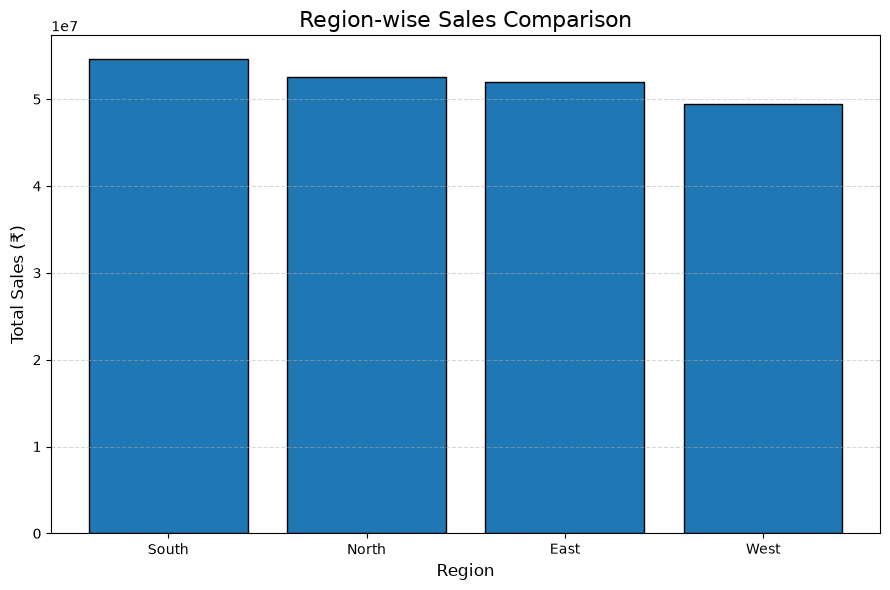

In [21]:
# Region-wise Sales Comparison

plt.figure(figsize=(9, 6))

plt.bar(
    region_summary["Region"],
    region_summary["Total_Sales"],
    edgecolor="black"
)

plt.title("Region-wise Sales Comparison", fontsize=16)
plt.xlabel("Region", fontsize=12)
plt.ylabel("Total Sales (₹)", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

# Save chart
plt.savefig("region_sales_bar_chart.png", dpi=300)

plt.show()

In [22]:
import os

print("Saved chart files:")

for file in os.listdir():
    if file.endswith(".png"):
        print(file)

Saved chart files:
category_sales_bar_chart.png
category_sales_pie_chart.png
monthly_sales_line_chart.png
quarterly_sales_chart.png
region_sales_bar_chart.png


In [23]:
# Generate Project Summary

best_category = category_summary.loc[
    category_summary["Total_Sales"].idxmax(), "Category"
]

best_region = region_summary.loc[
    region_summary["Total_Sales"].idxmax(), "Region"
]

summary_text = f"""
TIME SERIES & CATEGORY CHARTS
Project Summary
----------------------------

Total Orders: {len(df)}
Total Units Sold: {df['Quantity'].sum()}
Total Sales: Rs. {df['Sales'].sum():,.2f}
Total Profit: Rs. {df['Profit'].sum():,.2f}

Best Performing Category: {best_category}
Best Performing Region: {best_region}

Charts Created:
1. Monthly Sales Line Chart
2. Category Sales Bar Chart
3. Category Sales Pie Chart
4. Quarterly Sales Chart
5. Region-wise Sales Bar Chart

Chart Selection:
Line charts were used to show sales trends over time.
Bar charts were used to compare sales between categories and regions.
Pie charts were used to show the percentage contribution
of each category to total sales.

Formatting:
Titles, axis labels, legends, gridlines and percentage labels
were used to improve readability and interpretation.
"""

with open("project_summary.txt", "w", encoding="utf-8") as file:
    file.write(summary_text)

print(summary_text)
print("Project summary saved successfully!")


TIME SERIES & CATEGORY CHARTS
Project Summary
----------------------------

Total Orders: 5000
Total Units Sold: 27418
Total Sales: Rs. 208,535,936.00
Total Profit: Rs. 48,792,098.00

Best Performing Category: Electronics
Best Performing Region: South

Charts Created:
1. Monthly Sales Line Chart
2. Category Sales Bar Chart
3. Category Sales Pie Chart
4. Quarterly Sales Chart
5. Region-wise Sales Bar Chart

Chart Selection:
Line charts were used to show sales trends over time.
Bar charts were used to compare sales between categories and regions.
Pie charts were used to show the percentage contribution
of each category to total sales.

Formatting:
Titles, axis labels, legends, gridlines and percentage labels
were used to improve readability and interpretation.

Project summary saved successfully!


In [24]:
readme_content = """
# Time Series & Category Charts

## Project Overview
This project analyzes sales data using Python and data visualization techniques.
It explores sales trends over time, monthly and quarterly sales,
category-wise performance, and region-wise comparisons.

## Objectives
- Visualize sales trends over time using line charts.
- Perform monthly and quarterly sales aggregation.
- Compare product categories using bar charts.
- Visualize category sales distribution using a pie chart.
- Compare sales performance across regions.
- Save charts as PNG files.
- Generate a project summary.

## Dataset
This project uses a synthetically generated sales dataset containing 5,000 records
covering 2024 and 2025.

### Features
- Order_ID
- Date
- Category
- Product
- Region
- City
- Quantity
- Unit_Price
- Discount_Percent
- Gross_Sales
- Discount_Amount
- Sales
- Estimated_Cost
- Profit

## Tools & Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Visualizations
1. Monthly Sales Trend - Line Chart
2. Category-wise Sales - Bar Chart
3. Category Sales Distribution - Pie Chart
4. Quarterly Sales Trend - Line Chart
5. Region-wise Sales Comparison - Bar Chart

## Project Files
- sales_dataset.csv
- monthly_sales_summary.csv
- quarterly_sales_summary.csv
- category_sales_summary.csv
- region_sales_summary.csv
- product_sales_summary.csv
- city_sales_summary.csv
- project_summary.txt
- Chart PNG files
- Jupyter Notebook

## Conclusion
The project demonstrates how sales data can be summarized and visualized
to understand trends, category contributions, and regional performance.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [25]:
import os

print("===== PROJECT FILES =====\n")

for file in sorted(os.listdir()):
    if file.endswith((".csv", ".png", ".txt", ".md", ".ipynb")):
        print("✔", file)

===== PROJECT FILES =====

✔ README.md
✔ Syntecxhub_Time_Series_Category_Charts.ipynb
✔ category_sales_bar_chart.png
✔ category_sales_pie_chart.png
✔ category_sales_summary.csv
✔ city_sales_summary.csv
✔ monthly_sales_line_chart.png
✔ monthly_sales_summary.csv
✔ product_sales_summary.csv
✔ project_summary.txt
✔ quarterly_sales_chart.png
✔ quarterly_sales_summary.csv
✔ region_sales_bar_chart.png
✔ region_sales_summary.csv
✔ sales_dataset.csv


In [26]:
print("CSV Files:")
print([f for f in os.listdir() if f.endswith(".csv")])

print("\nChart Images:")
print([f for f in os.listdir() if f.endswith(".png")])

print("\nOther Project Files:")
print([f for f in os.listdir() if f.endswith((".txt", ".md", ".ipynb"))])

CSV Files:
['category_sales_summary.csv', 'city_sales_summary.csv', 'monthly_sales_summary.csv', 'product_sales_summary.csv', 'quarterly_sales_summary.csv', 'region_sales_summary.csv', 'sales_dataset.csv']

Chart Images:
['category_sales_bar_chart.png', 'category_sales_pie_chart.png', 'monthly_sales_line_chart.png', 'quarterly_sales_chart.png', 'region_sales_bar_chart.png']

Other Project Files:
['project_summary.txt', 'README.md', 'Syntecxhub_Time_Series_Category_Charts.ipynb']
